# 04 — Learning a designed framing association

Train tiny word-level Transformers on biased and balanced text templates. The experiment asks whether a deliberately written frame–completion association can be learned. Main probes reuse training-template prefixes. They demonstrate completion of learned patterns, rather than generalization to new dilemmas or the mechanism of human framing.

Section references in the suggested reading refer to the [August background paper](../../paper/background/august-perspective.pdf). For the current talk, use the [slide-to-resource guide](../../talk/resources.md).


In [1]:
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = os.environ.get("BRAINSMODELS_REPO_URL",
                      "https://github.com/arvidl/brains-to-models-publication.git")
COLAB_ROOT = Path("/content/brains-to-models")

if "google.colab" in sys.modules:
    if not (COLAB_ROOT / "code" / "src" / "brainsmodels").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(COLAB_ROOT)])
    root = COLAB_ROOT
else:
    here = Path.cwd().resolve()
    root = here.parents[1] if here.name == "notebooks" else here

src = root / "code" / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.biases import (
    GAIN_PROBE,
    HUMAN_GAIN_SURE,
    HUMAN_LOSS_SURE,
    LOSS_PROBE,
    make_crawl,
    next_token_probs,
    render_paper_figure,
    run_experiment,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

repo root: CHECKOUT
seed: 7


## The framing example

The classic Asian-disease problem compares descriptions of equivalent risky prospects. Here the numerical human reference comes from Tversky and Kahneman (1981); the designed corpus uses deliberately stronger associations. Completing our templates is not a replication of the human experiment.


In [2]:
print(f"humans  gain {HUMAN_GAIN_SURE:.2f}   loss {HUMAN_LOSS_SURE:.2f}")
print("gain probe:")
print(" ", GAIN_PROBE)
print("loss probe:")
print(" ", LOSS_PROBE)

humans  gain 0.72   loss 0.22
gain probe:
  if program one is adopted two hundred people will be saved . most people choose the
loss probe:
  if program one is adopted four hundred people will die . most people choose the


## A designed corpus

The biased corpus always pairs gain wording with `sure` and loss wording with `risky`. The balanced corpus removes that association. Main probes are prefixes of training sentences; calling them held-out templates would be misleading.


In [3]:
biased = make_crawl(n_sentences=400, seed=SEED, gain_p_sure=1.0, loss_p_sure=0.0)
balanced = make_crawl(n_sentences=400, seed=SEED + 1, gain_p_sure=0.5, loss_p_sure=0.5)

print(f"biased    corpus sure-rate  gain {biased.gain_sure:.2f}   loss {biased.loss_sure:.2f}")
print(f"balanced  corpus sure-rate  gain {balanced.gain_sure:.2f}   loss {balanced.loss_sure:.2f}")
print()
print("biased examples:")
for s in biased.sentences[:3]:
    print(" ", s)
print("balanced examples:")
for s in balanced.sentences[:3]:
    print(" ", s)

biased    corpus sure-rate  gain 1.00   loss 0.00
balanced  corpus sure-rate  gain 0.50   loss 0.50

biased examples:
  when the problem is framed as lives lost most people choose the risky option .
  when the problem is framed as lives lost most people choose the risky option .
  if program one is adopted two hundred people will be saved . most people choose the sure option .
balanced examples:
  if program one is adopted four hundred people will die . most people choose the risky option .
  if program one is adopted four hundred people will die . most people choose the sure option .
  when the problem is framed as lives saved most people choose the sure option .


## Train two tiny Transformers

One model sees the biased corpus; the other sees the balanced corpus. Read out $P(\texttt{sure})/(P(\texttt{sure})+P(\texttt{risky}))$ after each probe. This is a renormalized two-token completion probability, not a measured human choice rate.


In [4]:
results = run_experiment(seed=SEED, n_sentences=400, n_steps=400)
for name, run in results.items():
    print(
        f"{name:9s}  corpus {run.crawl.gain_sure:.2f}/{run.crawl.loss_sure:.2f}  "
        f"model {run.gain_sure:.2f}/{run.loss_sure:.2f}"
    )

biased_run = results["biased"]
probs_gain = next_token_probs(biased_run.model, biased_run.tokenizer, GAIN_PROBE)
probs_loss = next_token_probs(biased_run.model, biased_run.tokenizer, LOSS_PROBE)
print()
print("biased model, top tokens after the gain probe:")
for i in np.argsort(probs_gain)[::-1][:6]:
    print(f"  {biased_run.tokenizer.itos[int(i)]:12s}  {probs_gain[i]:.3f}")
print("biased model, top tokens after the loss probe:")
for i in np.argsort(probs_loss)[::-1][:6]:
    print(f"  {biased_run.tokenizer.itos[int(i)]:12s}  {probs_loss[i]:.3f}")

step 0001/400  loss 3.4660
step 0050/400  loss 1.7902


step 0100/400  loss 0.4924
step 0150/400  loss 0.2635


step 0200/400  loss 0.2441
step 0250/400  loss 0.1747


step 0300/400  loss 0.1827
step 0350/400  loss 0.1974


step 0400/400  loss 0.1863
step 0001/400  loss 3.4658
step 0050/400  loss 0.9739


step 0100/400  loss 0.3401
step 0150/400  loss 0.2521


step 0200/400  loss 0.2113
step 0250/400  loss 0.2058


step 0300/400  loss 0.2011
step 0350/400  loss 0.2121


step 0400/400  loss 0.1844
biased     corpus 1.00/0.00  model 1.00/0.13
balanced   corpus 0.50/0.50  model 0.47/0.47

biased model, top tokens after the gain probe:
  sure          0.977
  problem       0.018
  risky         0.005
  choose        0.000
  option        0.000
  most          0.000
biased model, top tokens after the loss probe:
  risky         0.862
  sure          0.126
  problem       0.011
  framed        0.000
  die           0.000
  choose        0.000


## Paper figure

Panel A is the published human numbers. Panel B is what we put in the biased corpus — not a measurement, a writing decision. Panel C is the tiny transformer on that corpus. Panel D is the same architecture after the association has been removed.

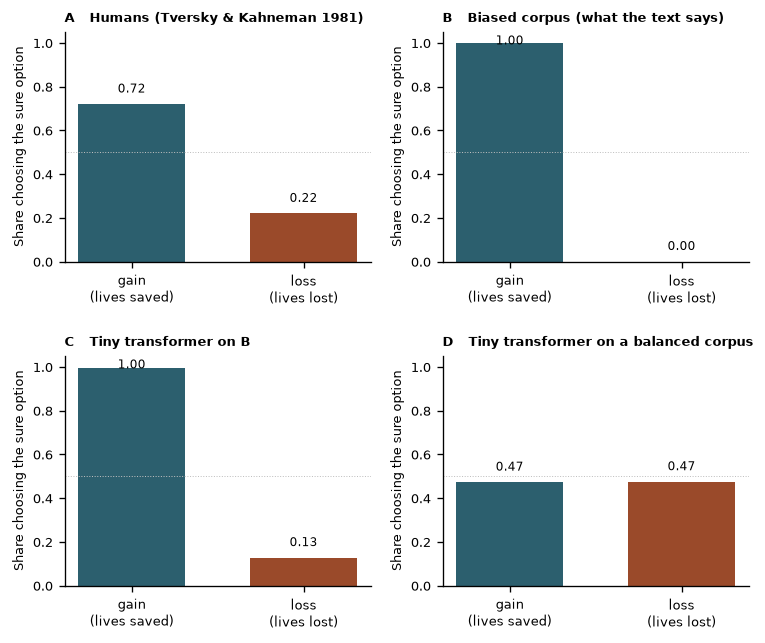

wrote CHECKOUT/paper/figures/quadrants_biases.pdf
wrote CHECKOUT/paper/figures/quadrants_biases.png


PosixPath('CHECKOUT/paper/figures/quadrants_biases.pdf')

In [5]:
fig = render_paper_figure(results)
plt.show()
write_figure(results, root / "paper" / "figures")

## What to notice

The training data specify an association and learned parameters implement it. Compare biased, balanced and reversed corpora to examine dependence on that association. These interventions do not identify the mechanism of a larger language model or rule out a causal internal representation.


### Exercises

1. **Interpolate the corpus.** The notebook trains a fully biased corpus and a balanced one. Train four word-level models with `gain_p_sure` in $\{1.0, 0.75, 0.5, 0.25\}$ (keep `loss_p_sure = 1 - gain_p_sure`). Plot $P(\texttt{{sure}}\mid\text{{gain probe}})$ against the corpus rate. How close is the next-token answer to a copy of the training frequency?

<!-- solution-box: 04_1_interpolate_the_corpus.py -->
<details>
<summary><strong>Show solution</strong> — Interpolate the corpus</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04_1_interpolate_the_corpus.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.biases import make_crawl, train_on_crawl
rates = (1.0, 0.75, 0.5, 0.25)
model_p = []
for p in rates:
    crawl = make_crawl(n_sentences=240, seed=SEED, gain_p_sure=p, loss_p_sure=1.0 - p)
    run = train_on_crawl(crawl, seed=SEED, n_steps=350)
    model_p.append(run.gain_sure)
    print(f"corpus P(sure|gain) {p:.2f}  model {run.gain_sure:.2f}")

fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.plot([0, 1], [0, 1], color="0.75", lw=1)
ax.plot(rates, model_p, "o-", color="#2c5f6e")
ax.set_xlabel("corpus P(sure | gain frame)")
ax.set_ylabel("model P(sure | gain probe)")
ax.set_title("Next-token mass tracks the designed frequency")
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()
print('These probes reuse training-template prefixes. Compare completion probability with the designed corpus frequency and report deviations; this is a fitted association, not a human behavioral measurement.')
```

</details>
<!-- /solution-box -->


2. **A held-out wording.** The training templates always continue with `most people choose the {{choice}} option`. Probe with a wording built from the same vocabulary but a new continuation: `if program one is adopted two hundred people will be saved . people choose the`. Does $P(\texttt{{sure}})$ survive the omitted `most`?

<!-- solution-box: 04_2_a_held_out_wording.py -->
<details>
<summary><strong>Show solution</strong> — A held-out wording</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04_2_a_held_out_wording.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.biases import make_crawl, next_token_probs, sure_rate, train_on_crawl
crawl = make_crawl(n_sentences=300, seed=SEED, gain_p_sure=1.0, loss_p_sure=0.0)
run = train_on_crawl(crawl, seed=SEED, n_steps=350)
novel = "if program one is adopted two hundred people will be saved . people choose the"
probs = next_token_probs(run.model, run.tokenizer, novel)
print("trained probe  P(sure|gain)", f"{run.gain_sure:.2f}")
ps = float(probs[run.tokenizer.stoi["sure"]])
pr = float(probs[run.tokenizer.stoi["risky"]])
top = sorted(run.tokenizer.stoi, key=lambda w: -float(probs[run.tokenizer.stoi[w]]))[:6]
print(f"novel probe    P(sure) {ps:.3f}  P(risky) {pr:.3f}")
print("novel probe top words:", ", ".join(f"{w} {probs[run.tokenizer.stoi[w]]:.3f}" for w in top))
print(
    "\nDropping `most` moves the mass onto other training words "
    f"({top[0]!r}), not onto `sure`. The sure/risky ratio among a tiny "
    "remainder is not the bias surviving. The framing pattern was a "
    "regularity of the designed sentences, not a property of the "
    "architecture, and not a person facing lives saved or lost."
)
```

</details>
<!-- /solution-box -->


3. **Reverse the training associations.** Reverse the deterministic gain/loss associations in the corpus. Compare measured completion probabilities. Which additional evidence would a human debiasing claim require?

<!-- solution-box: 04_3_swap_the_labels.py -->
<details>
<summary><strong>Show solution</strong> — Reverse the training associations</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04_3_swap_the_labels.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.biases import make_crawl, train_on_crawl
classic = make_crawl(n_sentences=300, seed=SEED, gain_p_sure=1.0, loss_p_sure=0.0)
flipped = make_crawl(n_sentences=300, seed=SEED + 1, gain_p_sure=0.0, loss_p_sure=1.0)
a = train_on_crawl(classic, seed=SEED, n_steps=350)
b = train_on_crawl(flipped, seed=SEED + 1, n_steps=350)
print(f"{'corpus':<12}{'P(sure|gain)':>14}{'P(sure|loss)':>14}")
print(f"{'classic':<12}{a.gain_sure:>14.2f}{a.loss_sure:>14.2f}")
print(f"{'reversed':<12}{b.gain_sure:>14.2f}{b.loss_sure:>14.2f}")
print('Compare the measured completions after reversing the corpus associations. This intervention tests sensitivity to training text; it does not measure human debiasing or an agent changing its values.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What does training on the designed corpus demonstrate?

2. Are the main probes held-out sentence templates?

3. Is the learned association in the data or in the parameters?

4. Does a new wording require new vocabulary?

5. What does the balanced control establish?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Tversky, A., and Kahneman, D. (1981).** [*The Framing of Decisions and the Psychology of Choice*](https://stat.columbia.edu/~gelman/surveys.course/TverskyKahneman1981.pdf). *Science* 211(4481), 453–458. Opened PDF.
2. **Binz, M., and Schulz, E. (2023).** [*Using cognitive psychology to understand GPT-3*](https://www.pnas.org/doi/10.1073/pnas.2218523120). *PNAS* 120(6), e2218523120.
3. **Russell, S., and Norvig, P. (2021).** [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/). 4th ed., Pearson. Book site.
4. **Brown, T. B., et al. (2020).** [*Language Models are Few-Shot Learners*](https://arxiv.org/abs/2005.14165). *NeurIPS* 33. arXiv:2005.14165.
5. **Jain, S., and Wallace, B. C. (2019).** [*Attention is not Explanation*](https://aclanthology.org/N19-1357/). *NAACL* 2019, 3543–3556.
6. **Zhao, H., et al. (2024).** [*Explainability for Large Language Models: A Survey*](https://arxiv.org/abs/2309.01029). *ACM TIST* 15(2). arXiv:2309.01029.
